# 03 · Grid building and upscaling

Builds a 22 × 22 × 12 grid over the 60 m below the Mississippian top: a corner-point grid that follows the
mapped top, and its flattened (stratigraphic) twin used for property modelling. Well-log porosity and a
clean-rock indicator are upscaled to the cells the wells cross. Run notebook 01 first.

Example assumptions: density porosity with a 2.71 g/cc limestone matrix, clean rock where GR < 60 API.

## Setup
Set `SX_EXAMPLE_PROJECT` to your KGS project folder (default `kgs_project/` next to this notebook).

In [1]:
import os
from pathlib import Path
import numpy as np, pandas as pd, pyarrow.parquet as pq
import matplotlib.pyplot as plt
%matplotlib inline
# SX_EXAMPLE_PROJECT: KGS project folder (las/, edges/, project.toml), see scripts/fetch_open_data.sh.
# SX_EXAMPLE_OUT: folder for figures and the small model files passed between notebooks.
PROJ = Path(os.environ.get("SX_EXAMPLE_PROJECT", "kgs_project")).resolve()
OUT = Path(os.environ.get("SX_EXAMPLE_OUT", "outputs")).resolve()
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 110})
def save(fig, name):
    fig.savefig(OUT / name, bbox_inches="tight")

## Well samples in the interval

In [2]:
from subsurfix import _native as nat
fin = pq.read_table(PROJ / "export/logs_final.parquet").to_pandas()
geo = pq.read_table(PROJ / "export/geometry.parquet").to_pandas()
tops = pq.read_table(PROJ / "export/tops.parquet").to_pandas()
mtop = tops[tops.top_name == "Mississippian"].set_index("well_id").elev_ft
d = fin.merge(geo[["well_id", "k", "elev_ft", "x_m", "y_m"]], on=["well_id", "k"])
d = d[d.well_id.isin(mtop.index)]
d["zrel_m"] = (mtop.reindex(d.well_id).values - d.elev_ft) * 0.3048          # depth below the top, m
d = d[(d.zrel_m >= 0) & (d.zrel_m < 60)].dropna(subset=["rhob_gcc", "gr_api"])
d["phi"] = ((2.71 - d.rhob_gcc.astype(float)) / 1.71).clip(0, 0.35)          # limestone density porosity
d["clean"] = (d.gr_api < 60).astype(np.int32)
print(len(d), "samples in", d.well_id.nunique(), "wells")

22230 samples in 59 wells


## Corner-point grid following the Mississippian top
The top is mapped by ordinary kriging of the well picks on the grid nodes; 12 layers of 5 m hang below it.

corner-point grid (22, 22, 12) | top depth 954.1 to 1029.5 m


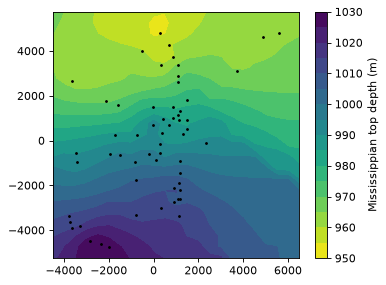

In [3]:
origin, cell, dims = (-4500.0, -5250.0, 0.0), (500.0, 500.0, 5.0), (22, 22, 12)
nx, ny, nz = dims
xs = origin[0] + cell[0] * np.arange(nx + 1)
ys = origin[1] + cell[1] * np.arange(ny + 1)
XN, YN = np.meshgrid(xs, ys)
wxy = d.groupby("well_id")[["x_m", "y_m"]].first()
pick = np.column_stack([wxy.x_m, wxy.y_m, np.zeros(len(wxy))])
top_m = -mtop.reindex(wxy.index).to_numpy() * 0.3048                      # depth below datum, m
nodes = np.column_stack([XN.ravel(), YN.ravel(), np.zeros(XN.size)])
top, _ = nat.ordinary_kriging(pick, top_m, nodes, "spherical", 0.0, float(np.var(top_m)), 6000.0)
cpg = nat.CornerPointGrid.from_surfaces(xs, ys, np.array([top + cell[2] * k for k in range(nz + 1)]))
print("corner-point grid", cpg.dims, "| top depth", top.min().round(1), "to", top.max().round(1), "m")
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.contourf(XN, YN, top.reshape(XN.shape), 15, cmap="viridis_r"); ax.plot(wxy.x_m, wxy.y_m, "k.", ms=3)
fig.colorbar(im, label="Mississippian top depth (m)"); ax.set_aspect("equal"); save(fig, "03_top_surface.png")

## Upscale to cells
Samples are averaged per cell (arithmetic for porosity, most frequent code for the indicator); cells with fewer
than 3 samples are left empty. Upscaling is done on the flattened grid, whose cells map one-to-one to the
corner-point cells.

622 porosity cells and 622 indicator cells of 5808


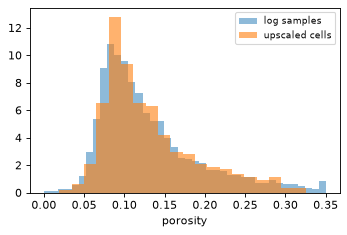

In [4]:
pts = d[["x_m", "y_m", "zrel_m"]].to_numpy(np.float64)
idx, phi_up, cnt = nat.upscale_continuous(origin, cell, dims, pts, d.phi.to_numpy(np.float64), "arithmetic", 3)
idf, clean_up, _ = nat.upscale_facies(origin, cell, dims, pts, d.clean.to_numpy(), 3)
print(len(idx), "porosity cells and", len(idf), "indicator cells of", np.prod(dims))
fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(d.phi, 40, density=True, alpha=0.5, label="log samples"); ax.hist(phi_up, 20, density=True, alpha=0.6, label="upscaled cells")
ax.set_xlabel("porosity"); ax.legend(fontsize=8); save(fig, "03_upscaling_hist.png")

## Save for the next notebooks

In [5]:
np.savez_compressed(OUT / "grid_upscaled.npz", origin=origin, cell=cell, dims=dims, xs=xs, ys=ys, top=top,
                    idx=idx, phi_up=phi_up, idf=idf, clean_up=clean_up)
print("saved grid_upscaled.npz")

saved grid_upscaled.npz
